# Diabetes Prediction Using ML Classification Algorithms
Reproduction of **Nahzat & Yağanoğlu (2021)** — *Makine Öğrenimi Sınıflandırma Algoritmalarını Kullanarak Diyabet Tahmini*, EJOSAT Special Issue 24, pp. 53–59.  
Pima Indian Diabetes Dataset · 5 classifiers (KNN, RF, SVM, ANN, DT) · 3 feature setups (Tables 3, 4, 5) · accuracy / precision / recall / F1 + confusion matrices.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## 2. Dataset (paper §3.1)
Pima Indian Diabetes Dataset (UCI): **768 records**, **9 attributes** including `Outcome` — 268 tested positive, 500 tested negative.

In [2]:
diabetes = pd.read_csv("datasets/diabetes.csv")
diabetes

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
# Pregnancies -> تعداد بارداری‌ها
# Glucose -> قند خون
# BloodPressure -> فشار خون
# SkinThickness -> ضخامت چین پوستی
# Insulin -> انسولین
# BMI -> شاخص توده بدنی
# DiabetesPedigreeFunction -> شاخص سابقه خانوادگی دیابت
# Age -> سن
# Outcome -> نتیجه‌(دیابت دارد یا خیر)

(diabetes == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

## 3. Preprocessing (paper §3.2)
There are no missing (NaN) values, but several features contain meaningless **zeros**. Per the paper, the mean **and** median are computed separately for diabetic and non-diabetic patients and the zeros are replaced accordingly (median is used for the heavily skewed `Insulin`, mean for the rest).

In [4]:
# zeros -> NaN, then fill each NaN with its Outcome-group statistic (mean/median)
zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
diabetes[zero_features] = diabetes[zero_features].replace(0, np.nan)
for feature in zero_features:
    stat = "median" if feature == "Insulin" else "mean"
    diabetes[feature] = diabetes.groupby("Outcome")[feature].transform(
        lambda s, stat=stat: s.fillna(getattr(s, stat)())
    )

((diabetes == 0) | diabetes.isna()).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

### 3.1 Two EDA-derived features (paper §3.3)
A diabetic is described as anyone who has a blood pressure of **more than 80** and a glucose level of **more than 105**.

In [5]:
# EDA-derived features
diabetes["HighBloodPressure"] = (diabetes["BloodPressure"] > 80).astype(int)
diabetes["HighGlucose"] = (diabetes["Glucose"] > 105).astype(int)

diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,HighBloodPressure,HighGlucose
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1,0,1
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0,0,0
2,8,183.0,64.0,33.0,169.5,23.3,0.672,32,1,0,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,0,1


### 3.2 Train/test split & normalization
70% for training+validation, 30% for testing (stratified, `random_state=1`). Each feature setup gets its own `MinMaxScaler` fitted **only** on its training split.

| Setup | Features | Paper |
|---|---|---|
| `extended` | all 8 + the 2 new features | Table 3 |
| `normal` | the 8 original features | Table 4 |
| `reduced` | without SkinThickness, DiabetesPedigreeFunction and the 2 new features | Table 5 |

In [6]:
X = diabetes.copy()
y = X.pop("Outcome")

extended_features = list(X.columns)  # 8 original + 2 new (Table 3)
normal_features = [f for f in extended_features if f not in ("HighBloodPressure", "HighGlucose")]  # Table 4
reduced_features = [f for f in normal_features if f not in ("SkinThickness", "DiabetesPedigreeFunction")]  # Table 5

In [7]:
SETUP_TITLES = {
    "extended": "all features + 2 new (Table 3)",
    "normal": "original 8 features (Table 4)",
    "reduced": "without SkinThickness, Pedigree & 2 new (Table 5)",
}


def make_split(features):
    """70% train+validation / 30% test, stratified; MinMax normalization per setup."""
    X_train, X_test, y_train, y_test = train_test_split(
        X[features], y, test_size=0.3, random_state=1, stratify=y
    )
    scaler = MinMaxScaler()
    X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)
    X_test = pd.DataFrame(scaler.transform(X_test), columns=features, index=X_test.index)
    return X_train, X_test, y_train, y_test


splits = {
    "extended": make_split(extended_features),
    "normal": make_split(normal_features),
    "reduced": make_split(reduced_features),
}

{setup: (f"train={len(s[0])}", f"test={len(s[1])}") for setup, s in splits.items()}

{'extended': ('train=537', 'test=231'),
 'normal': ('train=537', 'test=231'),
 'reduced': ('train=537', 'test=231')}

## 4. Evaluation measures (paper §3.4)
Confusion matrix plus accuracy (1), recall (2), precision (3) and F1-score (4); precision/recall/F1 are reported for the positive class (diabetic).

In [8]:
from IPython.display import display


def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=[0, 1], yticklabels=[0, 1], annot_kws={"size": 14})
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def get_metrics(y_true, y_pred, technique):
    return {
        "Classification Technique": technique,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

In [9]:
metrics = {"extended": [], "normal": [], "reduced": []}


def run_model(model, label):
    """Fit/predict on all three feature setups; plot each confusion matrix, collect metrics."""
    for setup, (X_train, X_test, y_train, y_test) in splits.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        plot_confusion_matrix(y_test, y_pred, title=f"{label} — {SETUP_TITLES[setup]}")
        metrics[setup].append(get_metrics(y_test, y_pred, label))

## 5. Classification algorithms (paper §3.3)


--- KNN (k=5) ---


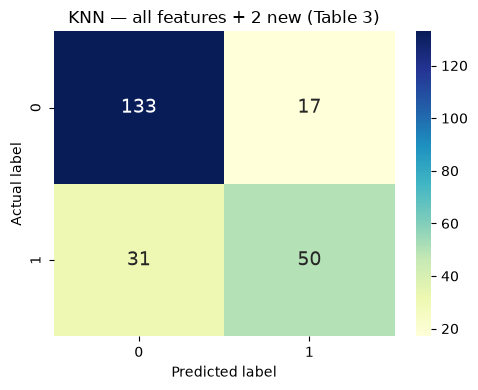

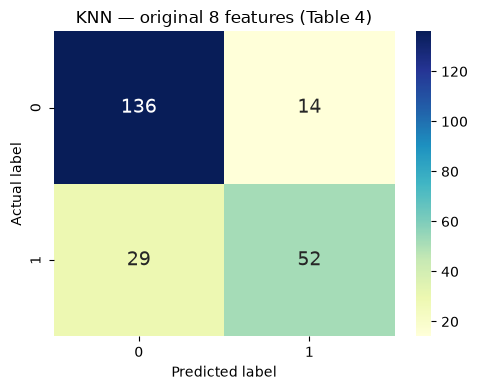

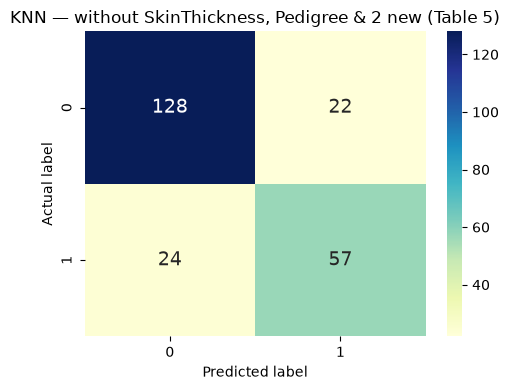

In [10]:
print("\n--- KNN (k=5) ---")
knn = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
run_model(knn, "KNN")


--- Random forests ---


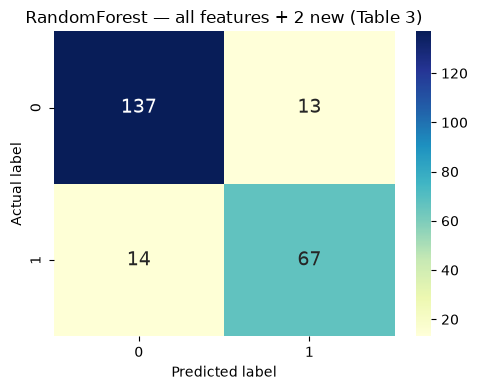

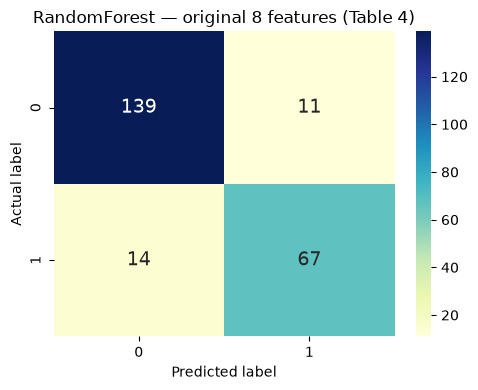

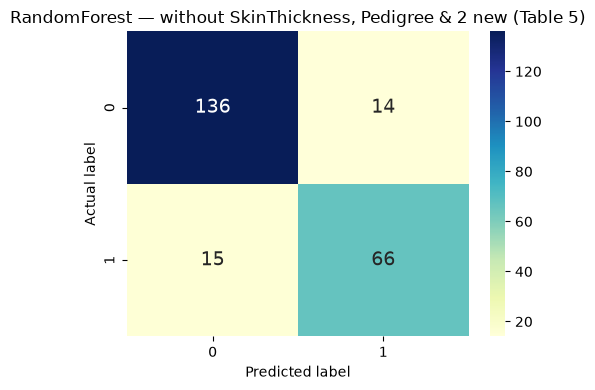

In [11]:
print("\n--- Random forests ---")
rf = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=1,
    n_jobs=-1
)
run_model(rf, "RandomForest")


--- SVM ---


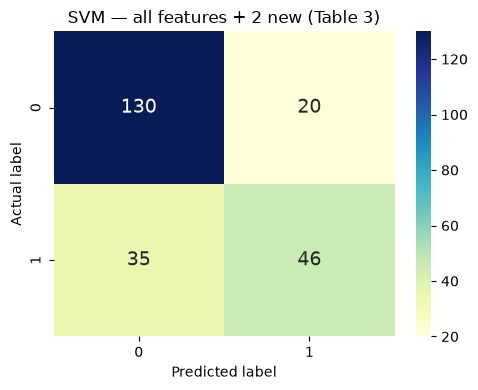

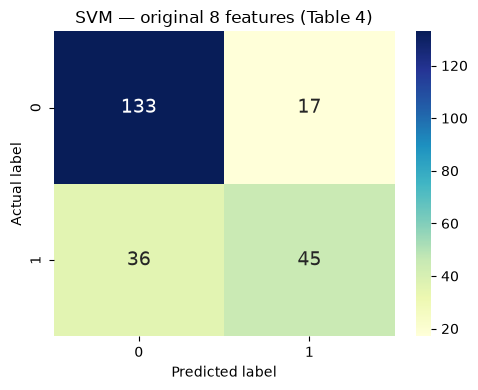

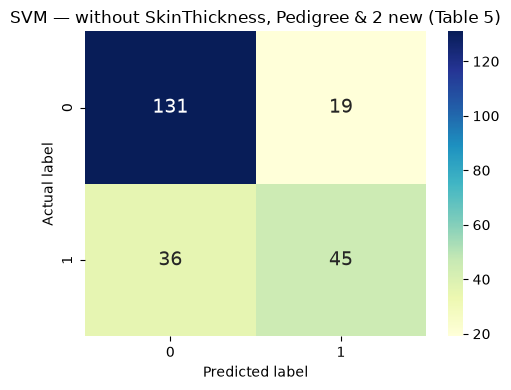

In [12]:
print("\n--- SVM ---")
svm = SVC(kernel="linear", C=1.0, random_state=1)
run_model(svm, "SVM")


--- ANN ---


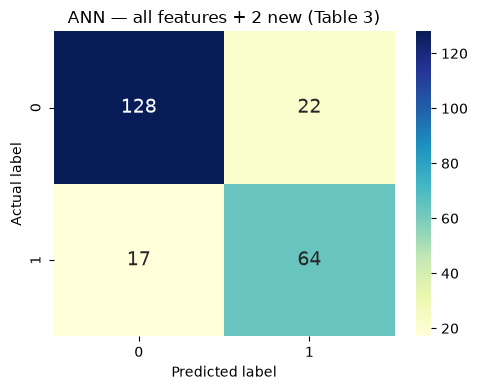

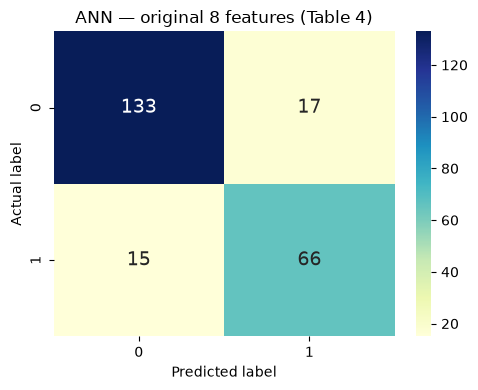

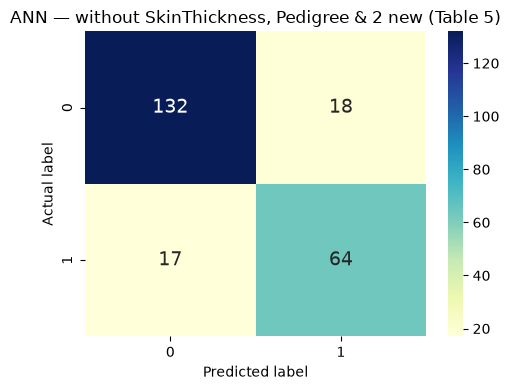

In [13]:
print("\n--- ANN ---")
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16, 8,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=1,
)
run_model(ann, "ANN")


--- Decision Tree ---


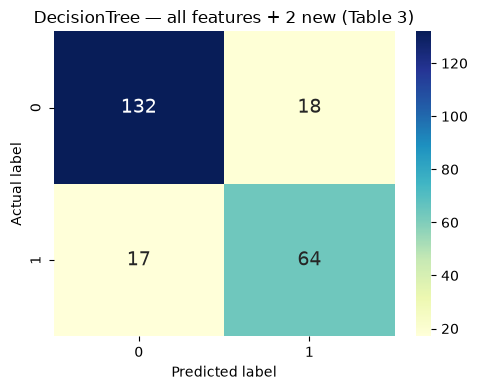

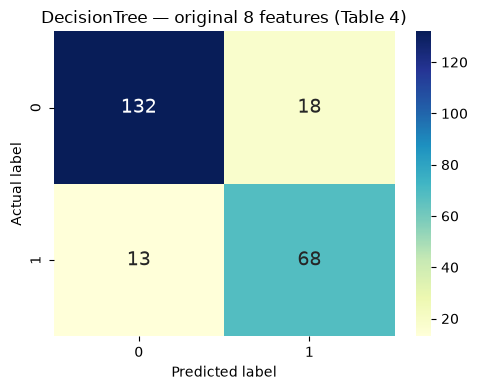

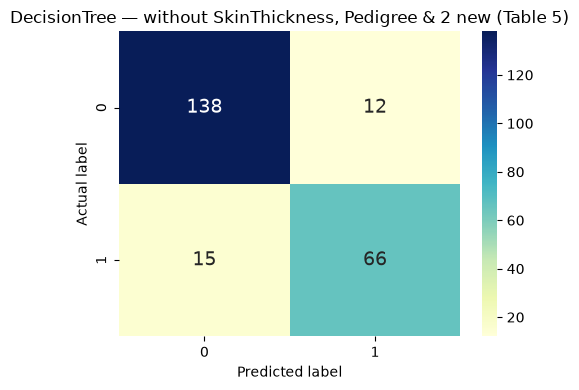

In [14]:
print("\n--- Decision Tree ---")
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=1
)
run_model(dt, "DecisionTree")

## 6. Results — accuracy / precision / recall / F1 (paper Tables 3, 4, 5)

In [15]:
results = {
    setup: pd.DataFrame(rows).set_index("Classification Technique")
    for setup, rows in metrics.items()
}

for setup, title in SETUP_TITLES.items():
    print(f"—— {title} ——")
    display(results[setup].style.format("{:.2%}"))
    print()

—— all features + 2 new (Table 3) ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,79.22%,74.63%,61.73%,67.57%
RandomForest,88.31%,83.75%,82.72%,83.23%
SVM,76.19%,69.70%,56.79%,62.59%
ANN,83.12%,74.42%,79.01%,76.65%
DecisionTree,84.85%,78.05%,79.01%,78.53%



—— original 8 features (Table 4) ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,81.39%,78.79%,64.20%,70.75%
RandomForest,89.18%,85.90%,82.72%,84.28%
SVM,77.06%,72.58%,55.56%,62.94%
ANN,86.15%,79.52%,81.48%,80.49%
DecisionTree,86.58%,79.07%,83.95%,81.44%



—— without SkinThickness, Pedigree & 2 new (Table 5) ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,80.09%,72.15%,70.37%,71.25%
RandomForest,87.45%,82.50%,81.48%,81.99%
SVM,76.19%,70.31%,55.56%,62.07%
ANN,84.85%,78.05%,79.01%,78.53%
DecisionTree,88.31%,84.62%,81.48%,83.02%


## 7. Accuracy comparison (paper Figure 8)
Accuracy of every classifier across the three feature setups — the paper's Figure 8 compares the setups with and without the two extracted features.

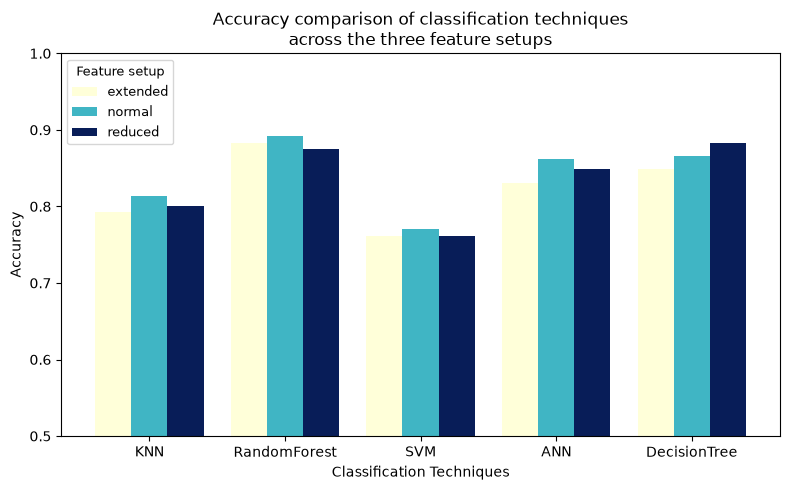

,extended,normal,reduced
Classification Technique,,,
KNN,79.22%,81.39%,80.09%
RandomForest,88.31%,89.18%,87.45%
SVM,76.19%,77.06%,76.19%
ANN,83.12%,86.15%,84.85%
DecisionTree,84.85%,86.58%,88.31%


In [16]:
accuracy = pd.DataFrame({setup: results[setup]["Accuracy"] for setup in results})

ax = accuracy.plot(kind="bar", figsize=(8, 5), ylim=(0.5, 1.0), colormap="YlGnBu", width=0.8)
ax.set_ylabel("Accuracy")
ax.set_xlabel("Classification Techniques")
ax.set_title("Accuracy comparison of classification techniques\nacross the three feature setups")
ax.legend(title="Feature setup", fontsize=9, title_fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

accuracy.style.format("{:.2%}")

## 8. Comparison with the paper's published numbers
Paper values from Tables 3–5. The paper does not state how precision/recall/F1 were averaged, so small deviations are expected; the ranking of classifiers is what matters.

In [17]:
paper_results = {
    "extended": {  # Table 3
        "KNN": (0.81, 0.80, 0.77, 0.78),
        "RandomForest": (0.8831, 0.88, 0.86, 0.87),
        "SVM": (0.77, 0.74, 0.74, 0.74),
        "ANN": (0.86, 0.85, 0.85, 0.85),
        "DecisionTree": (0.84, 0.82, 0.81, 0.82),
    },
    "normal": {  # Table 4
        "KNN": (0.82, 0.80, 0.79, 0.80),
        "RandomForest": (0.87, 0.86, 0.85, 0.85),
        "SVM": (0.77, 0.75, 0.75, 0.75),
        "ANN": (0.82, 0.81, 0.80, 0.80),
        "DecisionTree": (0.83, 0.82, 0.81, 0.81),
    },
    "reduced": {  # Table 5
        "KNN": (0.83, 0.81, 0.80, 0.81),
        "RandomForest": (0.88, 0.88, 0.86, 0.87),
        "SVM": (0.78, 0.76, 0.76, 0.76),
        "ANN": (0.83, 0.81, 0.80, 0.81),
        "DecisionTree": (0.84, 0.82, 0.81, 0.81),
    },
}

for setup, title in SETUP_TITLES.items():
    ours = results[setup]
    paper = pd.DataFrame(
        paper_results[setup], index=["Accuracy", "Precision", "Recall", "F1"]
    ).T.reindex(ours.index)
    paper.columns = ours.columns
    comparison = pd.concat({"paper": paper, "ours": ours, "delta": ours - paper}, axis=1)
    print(f"—— {title} ——")
    display(comparison.style.format("{:.2%}"))
    print(f"Best accuracy (ours): {ours['Accuracy'].idxmax()} = {ours['Accuracy'].max():.2%}\n")

—— all features + 2 new (Table 3) ——


Best accuracy (ours): RandomForest = 88.31%

—— original 8 features (Table 4) ——


Best accuracy (ours): RandomForest = 89.18%

—— without SkinThickness, Pedigree & 2 new (Table 5) ——


Best accuracy (ours): DecisionTree = 88.31%



**Conclusion (paper §5):** as in the paper, the **random forest** classifier achieves the highest accuracy, with the **ANN** second — reproduced here on the Pima Indian Diabetes dataset with mean/median zero-imputation, min-max normalization, a stratified 70/30 split and the two EDA-derived features.